### T5 трансформер для перевода с немецкого на английский

В этом задании вам предстоит обучить encoder-decoder трансформер переводить короткие предложения с английского на немецкий.

Токенизацию и блоки трансформера писать не придётся — будем пользоваться библиотекой `transformers`.

Наши задачи:
- Познакомиться с наиболее популярным методом токенизации текстов — byte pair encoding
- Научиться пользоваться токенизатором из `transformers`
- Подготовить данные
- Обучить готовую архитектуру T5-small под нашу задачу
- Исследовать разные стратегии декодирования с помощью обученной модели

In [31]:
! pip install sentencepiece

In [32]:
import math
from pathlib import Path
from typing import cast

import lightning as L
import torch
import torch.nn.functional as F
from torch import Tensor, nn
from torch.utils.data import DataLoader, Dataset
from transformers import T5ForConditionalGeneration, T5Tokenizer
from torch.optim import AdamW

from datasets import load_dataset, load_from_disk

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [33]:
torch.manual_seed(42)

#### Готовим данные

In [34]:
train_dataset = load_dataset("bentrevett/multi30k", split="train")
test_dataset = load_dataset("bentrevett/multi30k", split="test")

In [35]:
train_dataset[0]

{'en': 'Two young, White males are outside near many bushes.',
 'de': 'Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.'}

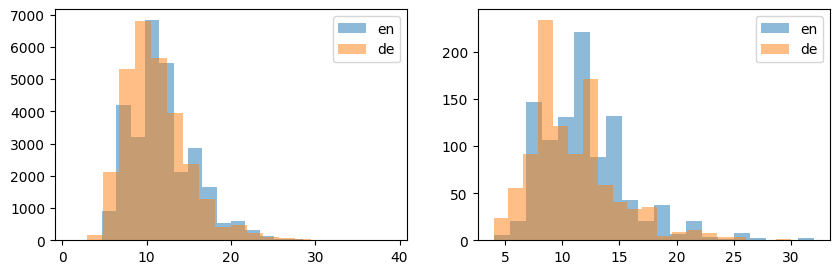

In [36]:
import matplotlib.pyplot as plt


def length_histogram(dataset, ax, bins=20) -> None:
    en_lengths = []
    de_lengths = []
    for sample in dataset:
        en_lengths.append(len(sample["en"].split(" ")))
        de_lengths.append(len(sample["de"].split(" ")))

    ax.hist(en_lengths, alpha=0.5, bins=bins, label="en")
    ax.hist(de_lengths, alpha=0.5, bins=bins, label="de")
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(10, 3))
length_histogram(train_dataset, axes[0])
length_histogram(test_dataset, axes[1])

Оставим только сравнительно короткие предложения, чтобы можно было чему-то научиться за короткое время

In [37]:
maxlen = 8


def filter_dataset(dataset, maxlen: int) -> list[dict[str, str]]:
    return [
        dataset[i]
        for i in range(len(dataset))
        if len(dataset[i]["en"].split(" ")) <= maxlen
    ]


train_filtered = filter_dataset(train_dataset, maxlen)
test_filtered = filter_dataset(test_dataset, maxlen)

print(len(train_filtered), len(test_filtered))

5144 174


##### Токенизация: byte-pair encoding

Построение:

Начинаем со словаря, состоящего из отдельных символов (начальные токены).
На каждом шаге:
1. Оцениваем частоту всех пар токенов внутри слов, находим самую частую
2. Добавляем её в список токенов и в таблицу слияний
3. Останавливаемся, когда достигаем максимального размера словаря


Применение:

1. Разбиваем текст на символы
2. Находим первое возможное слияние в таблице и применяем его
3. Останавливаемся, когда дальнейшие слияния невозможны

<img src="https://lena-voita.github.io/resources/lectures/seq2seq/bpe/build_merge_table.gif" style="background:white" width="720"/>
<img src="https://lena-voita.github.io/resources/lectures/seq2seq/bpe/bpe_apply.gif" style="background:white" width="270"/>

Реализаций много, мы будем использовать токенизатор  из библиотеки `transformers`, где помимо самого подготовленного токенизатора (`sentencepiece.SentencePieceProcessor`) много полезных методов для кодирования и декодирования.

Добавим при создании новый токен, который будет указывать на начало перевода

In [38]:
tokenizer: T5Tokenizer = T5Tokenizer.from_pretrained(
    "t5-small", padding_size="right", bos_token="</b>", legacy=False
)

In [39]:
print("Размер словаря: ", len(tokenizer))

Размер словаря:  32101


Посмотрим на примеры токенов, в них встречаются и целые слова из разных языков, и числительные, и знаки препинания:

In [40]:
import random

random.choices(list(tokenizer.get_vocab().items()), k=10)

[('die', 2498),
 ('▁FREE', 5858),
 ('ipped', 15437),
 ('▁genießen', 17734),
 ('▁dry', 2192),
 ('▁navig', 16867),
 ('artiste', 20591),
 ('▁socket', 16197),
 ('▁ausgewählt', 21561),
 ('▁medicament', 29258)]

Токенизатор в работе: кодирование и декодирование предложений на немецком и английском:

In [41]:
encoded_german = tokenizer.encode(train_dataset[0]["de"])
encoded_english = tokenizer.encode(train_dataset[0]["en"])
print(encoded_german)
print(tokenizer.decode(encoded_german))
print(encoded_english)
print(tokenizer.decode(encoded_english))

[11280, 16815, 7838, 15, 16282, 436, 256, 8671, 35, 16, 74, 13271, 2221, 49, 21162, 3992, 5, 1]
Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.</s>
[2759, 1021, 6, 1945, 5069, 7, 33, 1067, 1084, 186, 3, 30271, 5, 1]
Two young, White males are outside near many bushes.</s>


Об упаковке в батчи можно больше не беспокоиться — токенизатор умеет обрабатывать сразу пачку примеров

In [42]:
batch = [train_dataset[i]["en"] for i in range(4)]

encoded_batch = tokenizer.batch_encode_plus(
    batch, padding="longest", return_tensors="pt"
)
print(encoded_batch["input_ids"].shape)
print(encoded_batch.keys())

torch.Size([4, 19])
KeysView({'input_ids': tensor([[ 2759,  1021,     6,  1945,  5069,     7,    33,  1067,  1084,   186,
             3, 30271,     5,     1,     0,     0,     0,     0,     0],
        [    3,  8656,  1076,    16,   614,     3,   547,     7,    33,  2699,
             3,     9,  6079,  3197,    15,    63,   358,     5,     1],
        [   71,   385,  3202, 11908,   139,     3,     9,  5726,   577,  1840,
             5,     1,     0,     0,     0,     0,     0,     0,     0],
        [   71,   388,    16,     3,     9,  1692,  8677,    19,  4125,    30,
             3,     9, 15812,  2327,     3,     9,  2034,     5,     1]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])})


Возвращается два значения: `input_ids` — это наши токены, а `attention_mask` — это тензор, равный по размеру батчу токенов, где на месте `pad_token` стоят нули, в остальных позициях — единицы. Это нам понадобится потом.

А ещё можно кодировать сразу входные и выходные данные:

In [43]:
inputs = [train_dataset[i]["en"] + tokenizer.bos_token for i in range(4)]
targets = [train_dataset[i]["de"] for i in range(4)]

encoded_batch = tokenizer(
    inputs, text_target=targets, padding="longest", return_tensors="pt"
)
print(encoded_batch.keys())

KeysView({'input_ids': tensor([[ 2759,  1021,     6,  1945,  5069,     7,    33,  1067,  1084,   186,
             3, 30271,     5, 32100,     1,     0,     0,     0,     0,     0],
        [    3,  8656,  1076,    16,   614,     3,   547,     7,    33,  2699,
             3,     9,  6079,  3197,    15,    63,   358,     5, 32100,     1],
        [   71,   385,  3202, 11908,   139,     3,     9,  5726,   577,  1840,
             5, 32100,     1,     0,     0,     0,     0,     0,     0,     0],
        [   71,   388,    16,     3,     9,  1692,  8677,    19,  4125,    30,
             3,     9, 15812,  2327,     3,     9,  2034,     5, 32100,     1]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]), 'labels': tensor([[11280, 16815,  7838,

Используем это в `collate_fn` для сборки батчей:

In [44]:
def collate_fn(
    tokenizer: T5Tokenizer, batch: list[tuple[str, str]]
) -> tuple[Tensor, Tensor]:
    prompt = tokenizer.bos_token
    inputs, targets = zip(*[(pair["de"], prompt + pair["en"]) for pair in batch])
    encoded_batch = tokenizer(
        inputs, text_target=targets, padding="longest", return_tensors="pt"
    )
    return encoded_batch

In [45]:
batch = [train_dataset[i] for i in range(4)]
encoded_batch = collate_fn(tokenizer, batch)
print(encoded_batch.keys())

KeysView({'input_ids': tensor([[11280, 16815,  7838,    15, 16282,   436,   256,  8671,    35,    16,
            74, 13271,  2221,    49, 21162,  3992,     5,     1,     0,     0,
             0,     0],
        [11093,    49,    15, 16282,   181, 10956, 17757,    35,  1953,    23,
            35,    35,   236,   389, 13835,     7,  5672,  3734,     5,     1,
             0,     0],
        [  890,  5683,     7, 21644,     3,   157, 16024,    17,    16,   236,
          3012,  2989,   403,  8589,     5,     1,     0,     0,     0,     0,
             0,     0],
        [  890,  6362,    16,   665,     3, 16193,    35,   216,    51,    26,
          4186,   219,   645, 24484,    64,   474,   172,    17,   236, 16814,
             5,     1]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
 

In [46]:
print(encoded_batch["input_ids"].shape)
print(encoded_batch["attention_mask"].shape)
print(encoded_batch["labels"].shape)

torch.Size([4, 22])
torch.Size([4, 22])
torch.Size([4, 20])


Всё готово для получения минибатчей из датасетов:

In [47]:
train_loader = DataLoader(
    train_filtered,
    batch_size=32,
    shuffle=True,
    collate_fn=lambda batch: collate_fn(tokenizer, batch),
)
test_loader = DataLoader(
    test_filtered,
    batch_size=32,
    shuffle=False,
    collate_fn=lambda batch: collate_fn(tokenizer, batch),
)

#### Задание 1 (2 балла). DataModule

Реализуйте подкласс `lightning.LightningDataModule` для работы с обучающим и тестовым датасетами

In [48]:
from lightning.pytorch.utilities.types import EVAL_DATALOADERS, TRAIN_DATALOADERS


class Multi30kDataset(L.LightningDataModule):
    train_dataset: Dataset
    test_dataset: Dataset
    tokenizer: T5Tokenizer

    def __init__(self, maxlen: int = 0, batch_size: int = 32) -> None:
        self.maxlen = maxlen
        self.batch_size = batch_size
        self.tokenizer = T5Tokenizer.from_pretrained(
            "t5-small", padding_size="right", bos_token="</b>", legacy=False
        )
        self.train_dataset = None
        self.test_dataset = None

    def collate_fn(self, batch) -> tuple[Tensor, Tensor]:
        prompt = self.tokenizer.bos_token
        inputs, targets = zip(*[(pair["de"], prompt + pair["en"]) for pair in batch])
        encoded_batch = self.tokenizer(
            inputs, text_target=targets, padding="longest", return_tensors="pt"
        )
        return encoded_batch

    def setup(self, stage):
        if stage == "fit":
            train_dataset = load_dataset("bentrevett/multi30k", split="train")
            self.train_dataset = filter_dataset(train_dataset, self.maxlen)
        elif stage == "test":
            test_dataset = load_dataset("bentrevett/multi30k", split="test")
            self.test_dataset = filter_dataset(test_dataset, self.maxlen)

    def train_dataloader(self) -> TRAIN_DATALOADERS:
        if self.train_dataset is None:
            self.setup("fit")
        return DataLoader(
            self.train_dataset,
            batch_size=self.batch_size,
            shuffle=True,
            collate_fn=self.collate_fn,
        )
    
    def test_dataloader(self) -> EVAL_DATALOADERS:
        if self.test_dataset is None:
            self.setup("test")
        return DataLoader(
            self.test_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            collate_fn=self.collate_fn,
        )

In [49]:
multi30k = Multi30kDataset(maxlen=8, batch_size=12)

#### Задание 2 (4 балла). Обучение T5

paper: https://arxiv.org/abs/1910.10683

Обучите `t5-small` на наших данных, длительность обучения — на ваше усмотрение. В [документации](https://huggingface.co/docs/transformers/model_doc/t5) вы найдёте примеры использования, которые помогут вам разобраться в интерфейсе модели.

In [50]:
t5 = T5ForConditionalGeneration.from_pretrained("t5-small")

Обернём в `LightningModule`

In [51]:
import lightning as L
from lightning.pytorch.utilities.types import STEP_OUTPUT, OptimizerLRScheduler


class Seq2Seq(L.LightningModule):
    def __init__(
        self,
        model: nn.Module,
        tokenizer: T5Tokenizer,
        lr: float = 0.01,
    ) -> None:
        super().__init__()
        self.model = model
        self.tokenizer = tokenizer
        self.lr = lr

    def training_step(self, batch: dict[str, Tensor], batch_idx: int) -> STEP_OUTPUT:
        outputs = self.model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"], labels=batch["labels"])
        loss = outputs.loss
        self.log("loss", loss, prog_bar=True)
        return loss

    def configure_optimizers(self) -> OptimizerLRScheduler:
        optimizer = AdamW(self.model.parameters(), lr=self.lr)
        return optimizer

In [52]:
trainer = L.Trainer(
    accelerator="auto", max_epochs=25, limit_train_batches=None, logger=False
)
seq2seq = Seq2Seq(t5, multi30k.tokenizer, lr=1e-4)
trainer.fit(model=seq2seq, train_dataloaders=multi30k.train_dataloader())

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/vladimir/dl_hw/.venv/lib/python3.13/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:701: Checkpoint directory /home/vladimir/dl_hw/.venv/hw8/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type                       | Params | Mode
------------------------------------------------------------
0 | model | T5ForConditionalGeneration | 60.5 M | eval
------------------------------------------------------------
60.5 M    Trainable params
0         Non-trainable params
60.5 M    Total params
242.026   Total estimated model params size (MB)
0         Modules in train mode
277       Modules in eval mode
/home/vladimi

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=25` reached.


#### Задание 3 (2 балла). Генерация перевода

Сгенерируйте перевод для одного батча из тестового датасета (используйте метод `t5.generate()`), используя разные стратегии декодирования:
- *greedy decoding*
- *multinomial sampling*
- *beam-search multinomial sampling*

Эти стратегии (а также другие стратегии декодирования) можно задавать через `transformers.GenerationConfig`, который можно передать в метод `.generate()` нашей модели.
Выберите параметры, которые, на ваш взгляд, работают лучше всего.

In [53]:
from transformers import GenerationConfig

greedy_conf = GenerationConfig(
    max_new_tokens=20,
    num_beams=1,
    do_sample=False,
)

multinomial_conf = GenerationConfig(
    max_new_tokens=20,
    num_beams=1,
    do_sample=True,
    temperature=1.0,
    top_p=0.9,
)

beam_search_conf = GenerationConfig(
    max_new_tokens=20,
    num_beams=6,
    do_sample=True,
    temperature=0.9,
    no_repeat_ngram_size=2,
    early_stopping=True
)

In [54]:
batch = next(iter(multi30k.test_dataloader()))

with torch.no_grad():
    seq2seq.model.eval()
    greedy_preds = seq2seq.model.generate(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        generation_config=greedy_conf
    )
    multinomial_preds = seq2seq.model.generate(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        generation_config=multinomial_conf
    )
    beam_search_preds = seq2seq.model.generate(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        generation_config=beam_search_conf
    )

for i in range(len(batch["input_ids"])):
    print("Deutsch:", multi30k.tokenizer.decode(batch["input_ids"][i], skip_special_tokens=True))
    print("English:", multi30k.tokenizer.decode(batch["labels"][i], skip_special_tokens=True))
    print("Greedy-config translation:", multi30k.tokenizer.decode(greedy_preds[i], skip_special_tokens=True))
    print("Multinomial-config translation:", multi30k.tokenizer.decode(multinomial_preds[i], skip_special_tokens=True))
    print("BeamSearch-config translation:", multi30k.tokenizer.decode(beam_search_preds[i], skip_special_tokens=True))
    print()

Deutsch: Leute Reparieren das Dach eines Hauses.
English: People are fixing the roof of a house.
Greedy-config translation: People are repairing a roof of a house.
Multinomial-config translation: People that are cleaning a house's roof.
BeamSearch-config translation: People are preparing a house's roof.

Deutsch: Ein Typ arbeitet an einem Gebäude.
English: A guy works on a building.
Greedy-config translation: A guy working on a building.
Multinomial-config translation: A guy working on a building.
BeamSearch-config translation: A guy working on a building.

Deutsch: Drei Leute sitzen in einer Höhle.
English: Three people sit in a cave.
Greedy-config translation: Three people are sitting in a cave.
Multinomial-config translation: Three people are sitting in a cave.
BeamSearch-config translation: Three people are sitting in a cave.

Deutsch: Leute, die vor einem Gebäude stehen.
English: People standing outside of a building.
Greedy-config translation: People standing in front of a buildi